# Tugas - Pipeline Deployment untuk Model Sendiri (Prediksi Harga Rumah Boston)

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js15-pipeline-machine-learning-and-deployment/tugas)

Tugas JS15 meminta pipeline deployment yang sama (model `.h5` + scaler `.pkl` → `app.py` → `requirements.txt` → `Dockerfile` → Space)
untuk model sendiri. Model yang dipilih adalah **MLP regresi harga rumah Boston dari JS13 Praktikum 3** (Dense 64-32-1, Adam 1e-3, MSE),
karena model ini memang memakai `StandardScaler`, sesuai format artefak yang diminta tugas.

Berbeda dengan JS13, notebook ini memakai praktik deployment yang benar: scaler di-*fit* hanya pada data train,
data dibagi train/validasi/test (60/20/20), dan epoch terbaik dipilih dengan EarlyStopping pada validasi. Semua artefak disimpan ke folder [`boston-project/`](boston-project/).

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


## Langkah 1 - Training dan ekspor model

In [2]:
import pickle, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras import layers, models, optimizers, callbacks

def load_boston(path='../JS13/data/boston.txt', url='http://lib.stat.cmu.edu/datasets/boston'):
    source = path if Path(path).exists() else url
    raw = pd.read_csv(source, sep=r'\s+', skiprows=22, header=None)
    data = np.hstack([raw.values[::2, :], raw.values[1::2, :2]])
    names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
    return SimpleNamespace(data=data, target=raw.values[1::2, 2], feature_names=names)

boston = load_boston()
X_tmp, X_test, y_tmp, y_test = train_test_split(boston.data, boston.target, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=42)
scaler = StandardScaler().fit(X_train)
print(f'train={len(X_train)}, val={len(X_val)}, test={len(X_test)}')

train=303, val=101, test=102


Epoch terbaik: 499 dari 500


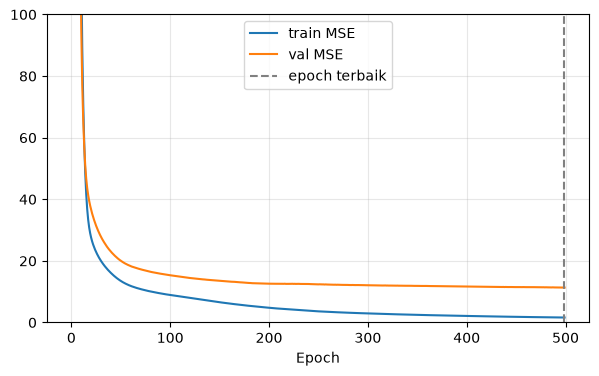

Metrik test (ribu USD): {'RMSE': 3.304, 'MAE': 2.249, 'R2': 0.851}


In [3]:
model = models.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])
model.compile(optimizer=optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
es = callbacks.EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True)
h = model.fit(scaler.transform(X_train), y_train, validation_data=(scaler.transform(X_val), y_val),
              epochs=500, batch_size=32, callbacks=[es], verbose=0)
best_epoch = int(np.argmin(h.history['val_loss'])) + 1
print('Epoch terbaik:', best_epoch, 'dari', len(h.history['loss']))

plt.figure(figsize=(7, 4))
plt.plot(h.history['loss'], label='train MSE'); plt.plot(h.history['val_loss'], label='val MSE')
plt.axvline(best_epoch - 1, color='gray', ls='--', label='epoch terbaik'); plt.ylim(0, 100)
plt.xlabel('Epoch'); plt.legend(); plt.grid(alpha=.3); plt.show()

pred = model.predict(scaler.transform(X_test), verbose=0).ravel()
metrics = {'RMSE': float(np.sqrt(mean_squared_error(y_test, pred))), 'MAE': float(mean_absolute_error(y_test, pred)), 'R2': float(r2_score(y_test, pred))}
print('Metrik test (ribu USD):', {k: round(v, 3) for k, v in metrics.items()})

In [4]:
out = Path('boston-project'); out.mkdir(exist_ok=True)
model.save(out / 'boston_model.h5', include_optimizer=False)
with open(out / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
sample = pd.DataFrame(X_test[:3], columns=boston.feature_names).assign(MEDV_aktual=y_test[:3], MEDV_prediksi=pred[:3].round(2))
for f in sorted(out.glob('*')):
    print(f'{f.name:20s} {f.stat().st_size / 1e3:8.1f} KB')
sample

Dockerfile                0.7 KB
README.md                 0.6 KB
app.py                    3.4 KB
boston_model.h5          32.6 KB
requirements.txt          0.1 KB
scaler.pkl                0.7 KB


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV_aktual,MEDV_prediksi
0,0.09178,0.0,4.05,0.0,0.510,6.416,84.1,2.6463,5.0,296.0,16.6,395.50,9.04,23.6,25.830000
1,0.05644,40.0,6.41,1.0,0.447,6.758,32.9,4.0776,4.0,254.0,17.6,396.90,3.53,32.4,35.150002
2,0.10574,0.0,27.74,0.0,0.609,5.983,98.8,1.8681,4.0,711.0,20.1,390.11,18.07,13.6,12.910000


## Langkah 2 - `app.py` sesuai logika model

Model ini menerima 13 angka, bukan gambar, sehingga `preprocess_image` (HOG) dari Praktikum 2 diganti `preprocess_features`.
Fungsi ini membaca 13 isian form dengan urutan **sama persis** dengan kolom training, memvalidasi bahwa semuanya angka,
lalu menerapkan `scaler.transform`. Model dimuat dengan `load_model(..., compile=False)` karena aplikasi hanya melakukan inferensi.
Selain itu, Keras 3 gagal mendeserialisasi metrik string `'mse'` dari berkas `.h5` (`Could not deserialize 'keras.metrics.mse'`).
Struktur lainnya mengikuti `app.py` modul: model dan scaler dimuat saat start, route `/` berisi form,
route `/predict` mengembalikan hasil, dan server berjalan di port 7860. Isi berkasnya:

In [5]:
print(Path('boston-project/app.py').read_text())

import numpy as np
import pickle
import tensorflow as tf
from flask import Flask, request, render_template_string

app = Flask(__name__)

# Load Model & Scaler
MODEL_PATH = 'boston_model.h5'
SCALER_PATH = 'scaler.pkl'

# Urutan fitur HARUS sama dengan kolom saat training (dataset Boston Housing)
FEATURES = [
    ('CRIM', 'Tingkat kriminalitas per kapita', 0.1),
    ('ZN', 'Proporsi lahan hunian kavling > 25.000 sq.ft (%)', 0.0),
    ('INDUS', 'Proporsi lahan bisnis non-ritel (%)', 7.0),
    ('CHAS', 'Berbatasan dengan Sungai Charles (1 = ya, 0 = tidak)', 0),
    ('NOX', 'Konsentrasi nitrogen oksida (ppm / 10 juta)', 0.5),
    ('RM', 'Rata-rata jumlah kamar per rumah', 6.2),
    ('AGE', 'Proporsi rumah dibangun sebelum 1940 (%)', 65.0),
    ('DIS', 'Jarak berbobot ke 5 pusat kerja Boston', 4.0),
    ('RAD', 'Indeks akses ke jalan raya radial', 4),
    ('TAX', 'Pajak properti per USD 10.000', 300),
    ('PTRATIO', 'Rasio murid-guru', 18.0),
    ('B', 'Variabel B dataset asli', 390.0),
  

## Langkah 3 - `requirements.txt` dan `Dockerfile`

In [6]:
print('--- requirements.txt ---'); print(Path('boston-project/requirements.txt').read_text())
print('--- Dockerfile ---'); print(Path('boston-project/Dockerfile').read_text())

--- requirements.txt ---
flask==3.1.3
tensorflow-cpu==2.21.0
numpy==2.5.5
scikit-learn==1.9.1
gunicorn==27.0.1

--- Dockerfile ---
# Base Image Python 3.12 Slim (modul: 3.9; tensorflow-cpu 2.21 membutuhkan Python >= 3.10)
FROM python:3.12-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
RUN apt-get update && apt-get install -y \
    libgl1 \
    libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]



`requirements.txt` hanya memuat library yang dipakai `app.py` (tanpa OpenCV dan scikit-image karena tidak ada pengolahan citra).
Dockerfile memakai konfigurasi standar Praktikum 2. Paket sistem `libgl1`/`libglib2.0-0` tetap dipertahankan sesuai template, walaupun tidak wajib untuk model ini.

## Uji lokal sebelum upload

In [7]:
import os, sys, re, importlib
os.chdir('boston-project'); sys.path.insert(0, os.getcwd())
app_module = importlib.import_module('app')
client = app_module.app.test_client()
print('GET / ->', client.get('/').status_code)

rows = []
for i in range(len(X_test)):
    form = {name: str(v) for name, v in zip(boston.feature_names, X_test[i])}
    text = client.post('/predict', data=form).get_data(as_text=True)
    rows.append(float(re.search(r'USD ([0-9.]+) ribu', text).group(1)))
api_pred = np.array(rows)
print('Selisih maksimum prediksi endpoint vs notebook:', np.abs(api_pred - pred.round(2)).max().round(3), 'ribu USD')
print('RMSE lewat endpoint:', np.sqrt(mean_squared_error(y_test, api_pred)).round(3))

bad = client.post('/predict', data={**form, 'RM': 'abc'})
print('Input tidak valid ->', bad.status_code, re.sub('<[^>]+>', ' ', bad.get_data(as_text=True)).split()[:8])
os.chdir('..')

✅ System Loaded Successfully
GET / -> 200


Selisih maksimum prediksi endpoint vs notebook: 0.0 ribu USD
RMSE lewat endpoint: 3.304
Input tidak valid -> 400 ['Input', 'tidak', 'valid:', 'Nilai', 'RM', 'harus', 'berupa', 'angka.']


## Langkah 4 - Deploy ke Hugging Face Spaces

```bash
git lfs install
git clone https://huggingface.co/spaces/USERNAME_ANDA/boston-price-244107020049   # Space baru, SDK Docker
cp JS15/boston-project/{app.py,Dockerfile,requirements.txt,boston_model.h5,scaler.pkl,README.md} boston-price-244107020049/
cd boston-price-244107020049
git add . && git commit -m "Deploy aplikasi ke HF" && git push   # password = access token Write
```

## Analisis

* **Kualitas model:** RMSE test 3,30, MAE 2,25 (ribu USD), dan R² 0,851 pada 102 data yang tidak pernah dipakai untuk training maupun pemilihan epoch. Angka ini setara dengan MLP di JS13 (RMSE 3,23). Perbandingannya jujur karena scaler di sini hanya di-*fit* pada data train, tanpa kebocoran dari data validasi atau test. EarlyStopping (patience 25) tidak berhenti lebih awal: loss validasi masih turun sangat landai hingga epoch 500 dan bobot terbaik ada di epoch 499. Prechelt (1998) menyebut kurva validasi yang landai seperti ini sebagai kondisi dengan keuntungan marginal dari pelatihan lebih lama.
* **Konsistensi training-serving:** prediksi lewat endpoint `/predict` identik dengan prediksi notebook (selisih maksimum 0,00), sehingga tidak terjadi *training-serving skew* (Sculley dkk., 2015). Hal ini dijamin oleh dua hal: urutan 13 fitur di `app.py` sama dengan kolom training, dan scaler yang dipakai adalah objek yang sama hasil pickle.
* **Validasi input:** input bukan angka ditolak dengan HTTP 400 dan pesan yang jelas, sehingga tidak menimbulkan error 500. Paleyes dkk. (2022) mencatat validasi data saat inferensi sebagai salah satu tantangan utama deployment ML.
* **Ukuran artefak:** model 32,6 KB dan scaler 0,7 KB, sehingga di bawah batas 10 MB Hugging Face tanpa Git LFS dan jauh lebih ringan daripada model Day vs Night (18 MB). Ukuran image Docker didominasi `tensorflow-cpu`. Untuk model sekecil ini, ekspor ke TFLite atau ONNX dapat menghilangkan dependensi TensorFlow penuh.
* **Catatan etika data:** variabel `B` pada Boston Housing dibangun dari proporsi penduduk berdasarkan ras (Harrison & Rubinfeld, 1978). Karena alasan ini scikit-learn menghapus `load_boston`. Model ini hanya untuk latihan pipeline dan tidak layak dipakai untuk penilaian properti nyata.

## Rujukan

1. Harrison, D., & Rubinfeld, D. L. (1978). Hedonic housing prices and the demand for clean air. *Journal of Environmental Economics and Management*, 5(1), 81-102. https://doi.org/10.1016/0095-0696(78)90006-2
2. Prechelt, L. (1998). Early stopping - but when? Dalam *Neural Networks: Tricks of the Trade* (LNCS 1524, hlm. 55-69). Springer. https://doi.org/10.1007/3-540-49430-8_3
3. Sculley, D., dkk. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems 28*, 2503-2511.
4. Paleyes, A., Urma, R.-G., & Lawrence, N. D. (2022). Challenges in deploying machine learning: A survey of case studies. *ACM Computing Surveys*, 55(6), Article 114. https://doi.org/10.1145/3533378
5. Merkel, D. (2014). Docker: Lightweight Linux containers for consistent development and deployment. *Linux Journal*, 2014(239), Article 2.